In [2]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, RandomizedSearchCV, cross_val_score, KFold
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score)
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier,
                              RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor,
                              HistGradientBoostingRegressor, StackingRegressor)
from sklearn.decomposition import PCA


In [3]:
dataset_filename = 'Aqua_Epoch_BIS_Water_Quality_Dataset.csv'
dataset_candidates = (
    Path('../data') / dataset_filename,
    Path('data') / dataset_filename,
    Path('../' + dataset_filename),
    Path(dataset_filename),
)
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError(f'Could not locate {dataset_filename}')
df = pd.read_csv(dataset_path)
df.head()

,pH,Hardness,TDS,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Calcium,Magnesium,Sodium,Potassium,Chloride,Nitrate,Fluoride,Iron,Alkalinity,Potability
0,7.159102,150.155773,16052.651840,5.685047,374.464185,352.121528,11.587073,75.046610,4.966698,61.504002,21.006579,62.345970,2.192344,135.643193,5.561354,1.520887,0.169315,116.950616,0.0
1,6.990053,212.120116,15569.182870,6.872750,319.992702,443.547183,18.268341,123.893737,2.868158,85.238809,28.953441,79.458626,10.197039,168.585701,61.612777,0.786435,0.065204,152.949912,0.0
2,7.110356,204.571035,8183.078691,5.986018,416.595049,311.932109,12.701190,67.312776,4.264031,77.150948,30.591307,62.537654,10.996049,97.220908,9.129196,0.688611,0.124803,153.344413,1.0
3,7.284110,-182.817891,14578.670700,8.454951,372.514273,498.519766,11.753549,58.285792,3.272094,59.718816,26.448595,104.771855,8.332848,165.030904,16.846849,-1.563750,0.180515,173.499347,0.0
4,5.500103,150.299555,25303.762810,7.147440,352.099179,526.743300,15.772748,51.344206,3.407067,58.647298,17.553237,110.628270,12.754797,196.460217,5.390290,1.300669,0.064911,106.874981,0.0


data cleaning


In [4]:
df.isnull().sum()

pH                 3990
Hardness           3890
TDS                3987
Chloramines        3890
Sulfate            3992
Conductivity       3890
Organic_carbon     3889
Trihalomethanes    3889
Turbidity          3990
Calcium            3890
Magnesium          3890
Sodium             3890
Potassium          3889
Chloride           3889
Nitrate            3989
Fluoride           3889
Iron               3889
Alkalinity         3889
Potability         3889
dtype: int64

In [5]:
df.skew().sort_values()

Hardness           -4.430364
Calcium            -0.097794
Alkalinity         -0.066752
Trihalomethanes    -0.063833
Magnesium          -0.050604
Sulfate            -0.029191
Organic_carbon     -0.008665
Chloramines         0.034847
Chloride            0.085542
Sodium              0.121803
Conductivity        0.284104
Potability          0.459533
Fluoride            1.137498
Nitrate             1.962361
Potassium           2.006569
Iron                2.045549
pH                  4.457617
Turbidity          12.610774
TDS                14.624314
dtype: float64

## 3. Exploratory analysis

The following plots summarize feature distributions and pairwise linear relationships. Correlation is useful for screening redundancy, but low correlation does not rule out nonlinear predictive value.

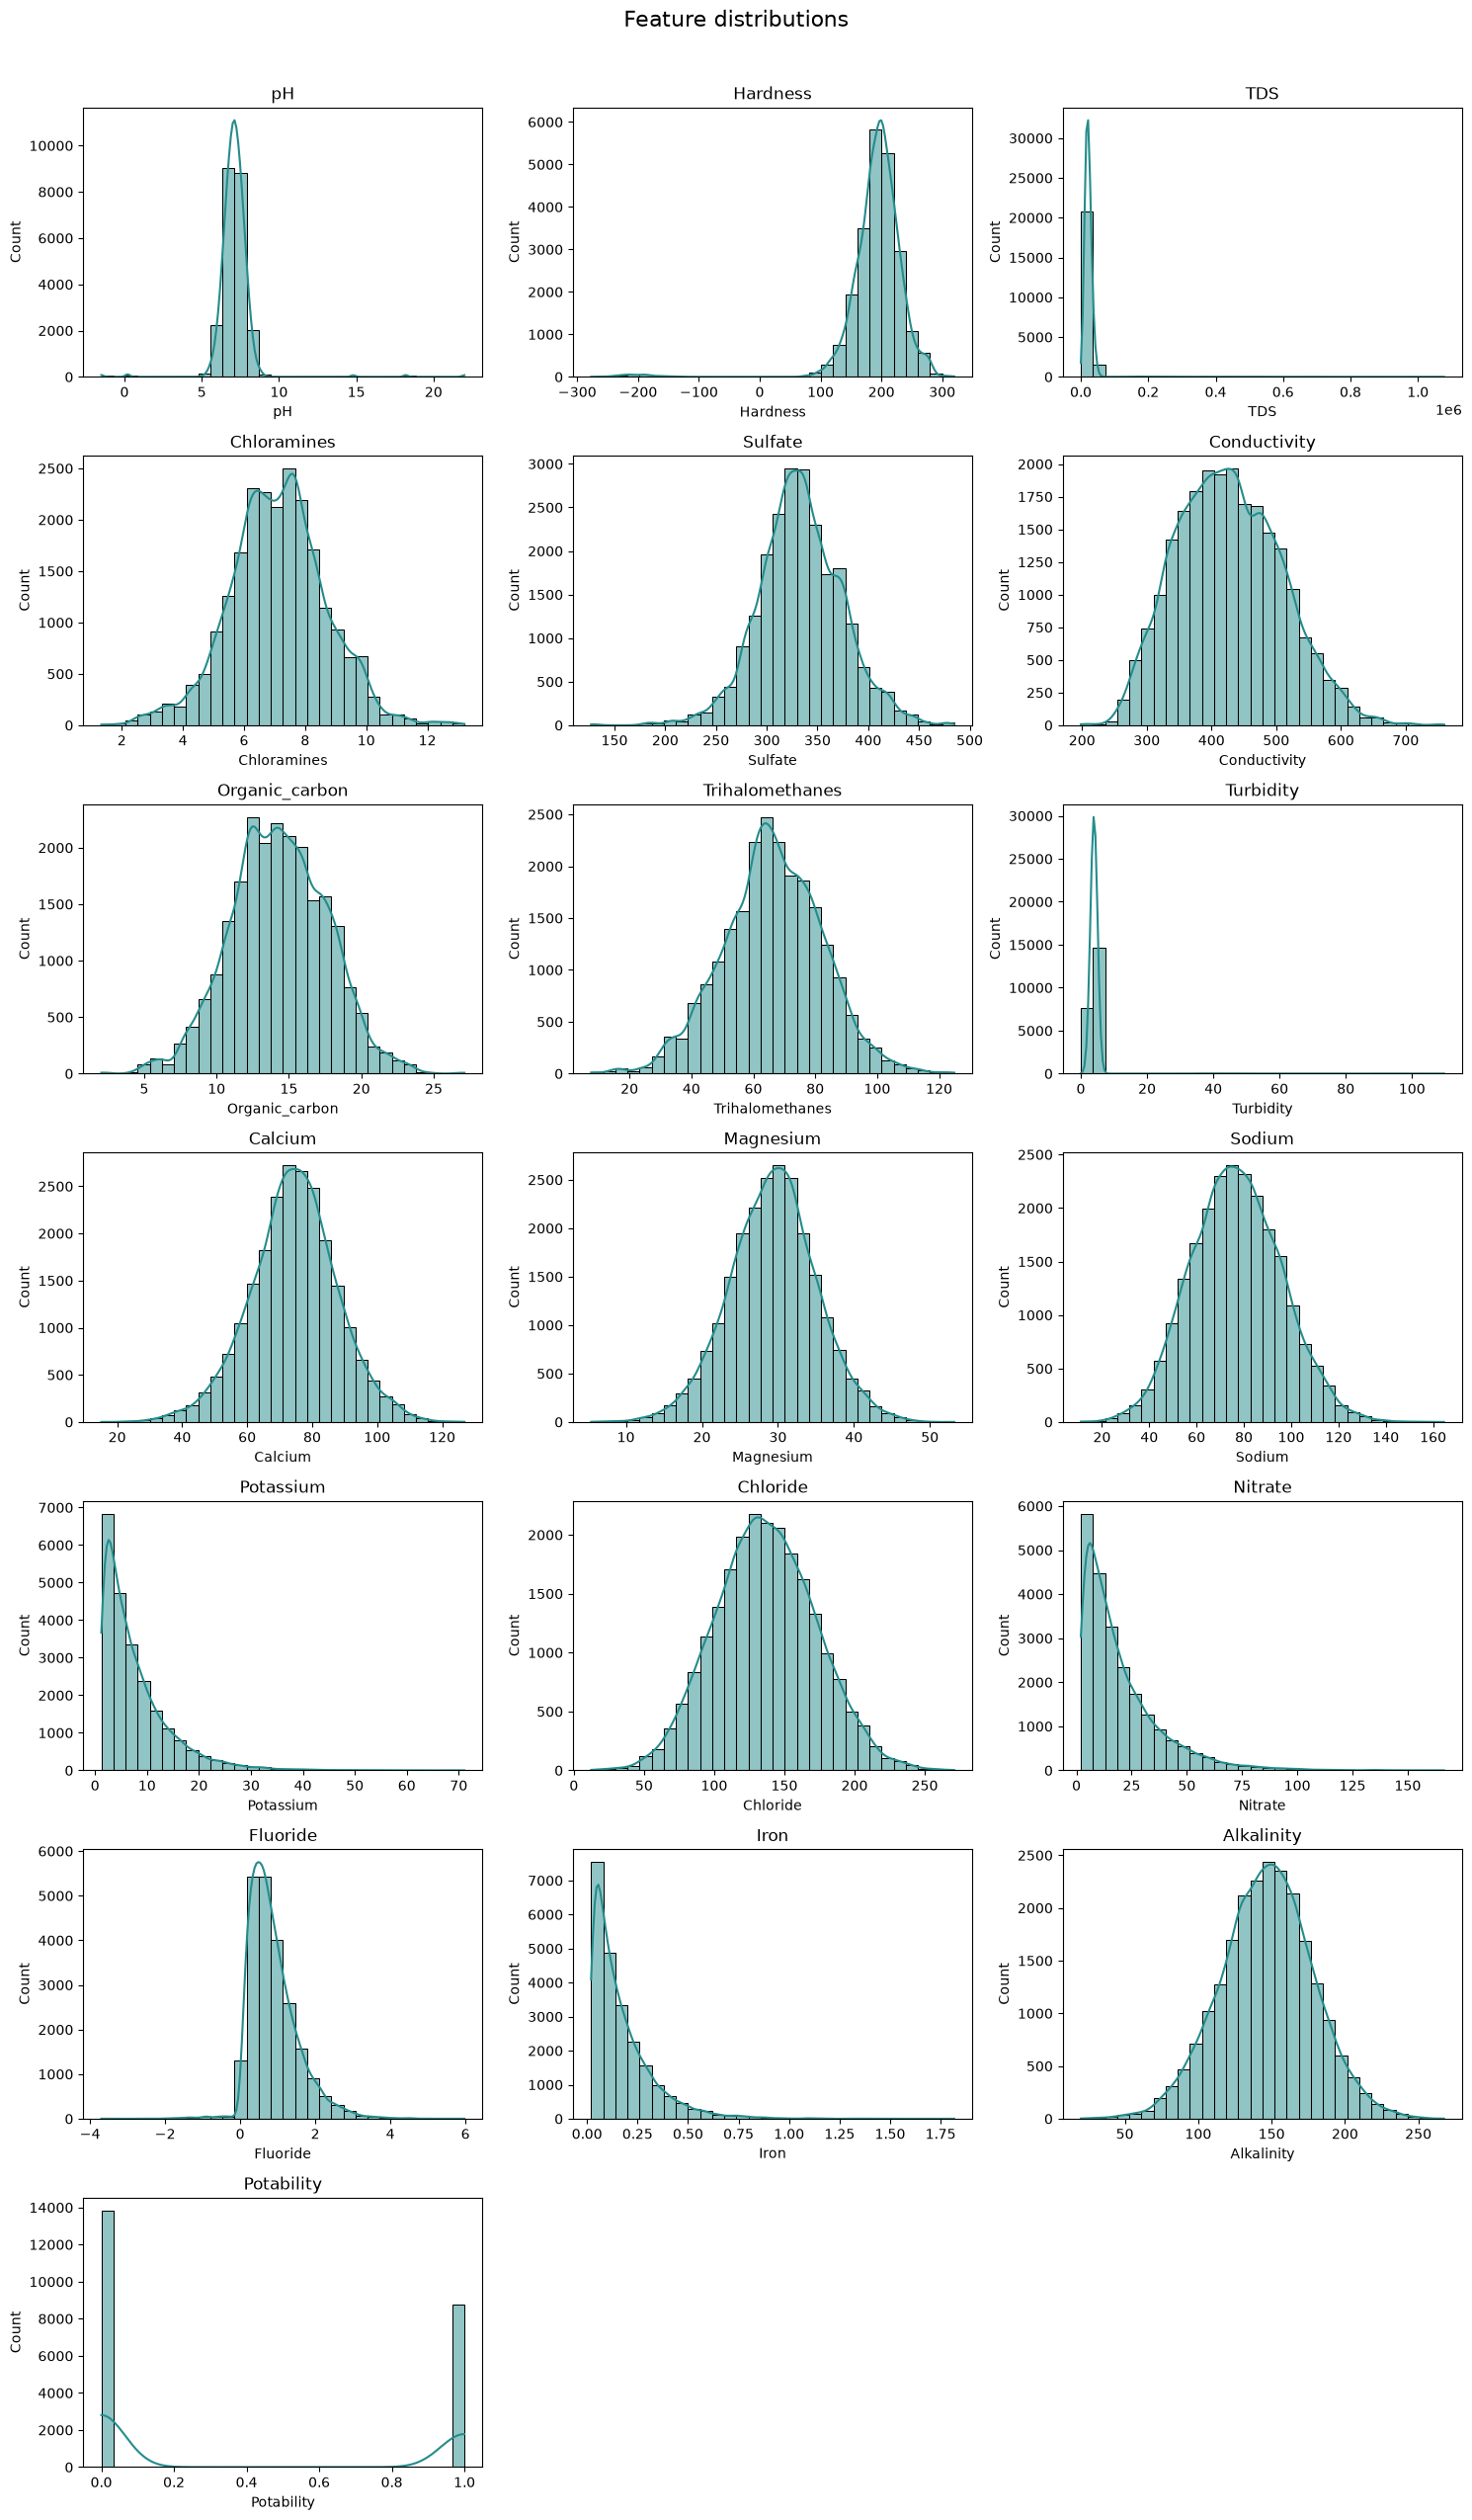

In [6]:
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
ncols = 3
nrows = int(np.ceil(len(numeric_cols)/ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.6*nrows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, numeric_cols):
    sns.histplot(df[col].dropna(), kde=True, bins=30, ax=ax, color='#258c8c')
    ax.set_title(col)
for ax in axes[len(numeric_cols):]: ax.remove()
plt.suptitle('Feature distributions', y=1.01, fontsize=16)
plt.tight_layout(); plt.show()

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt


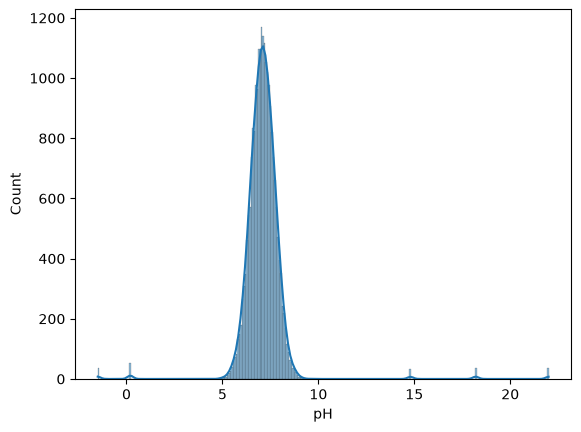

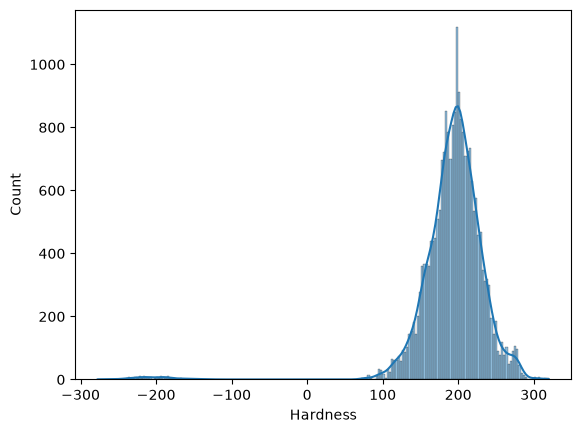

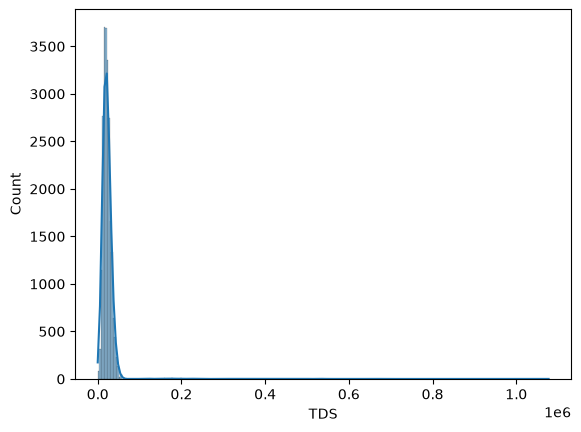

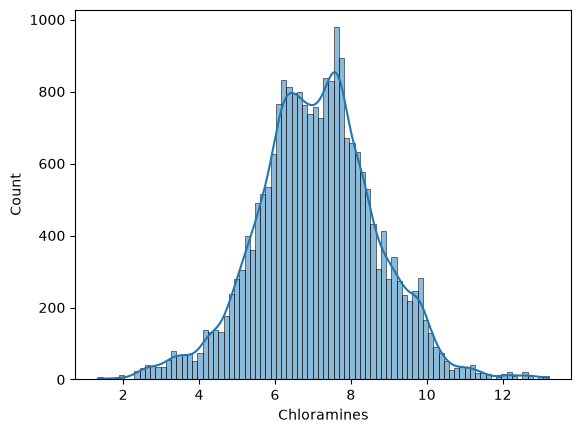

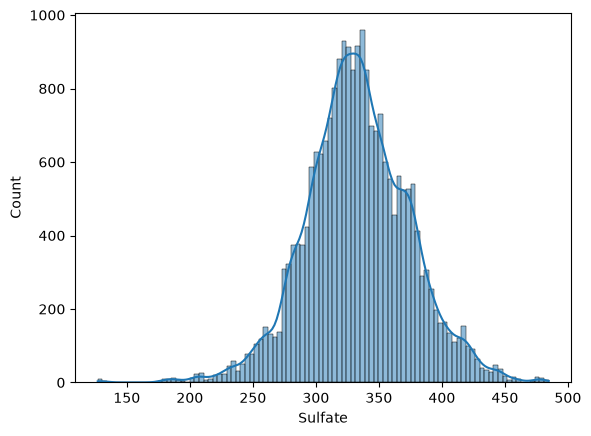

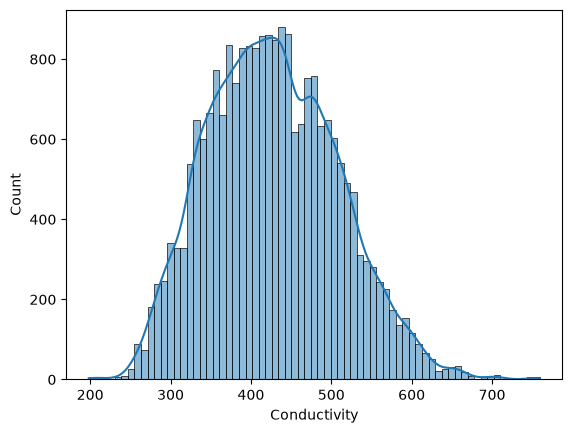

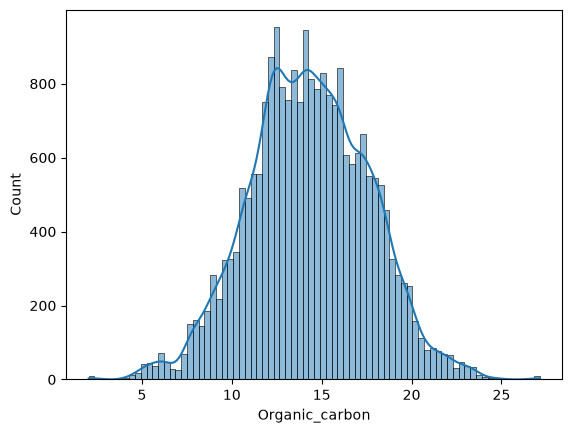

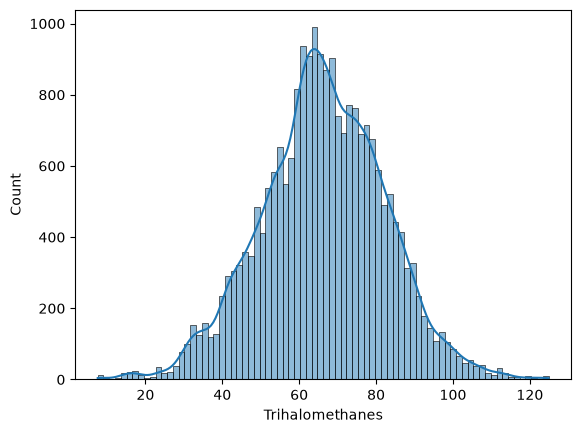

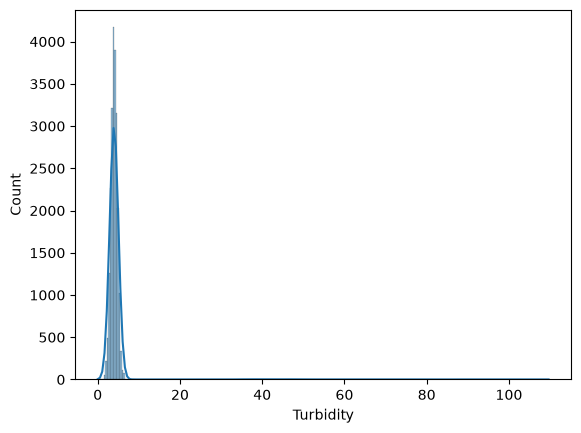

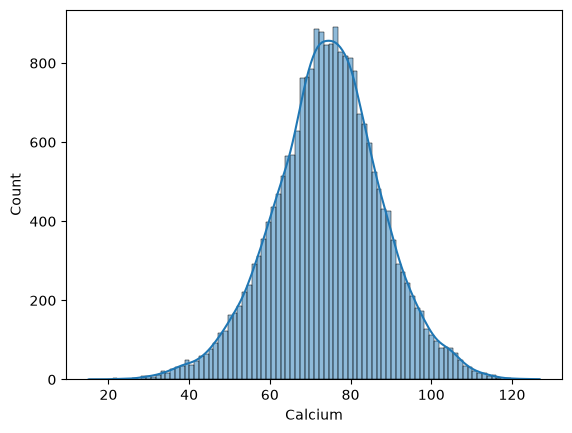

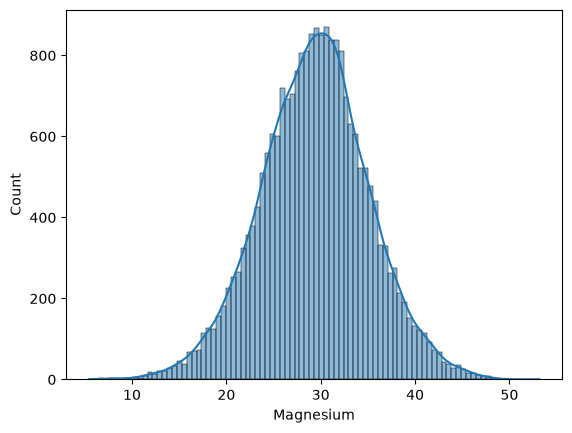

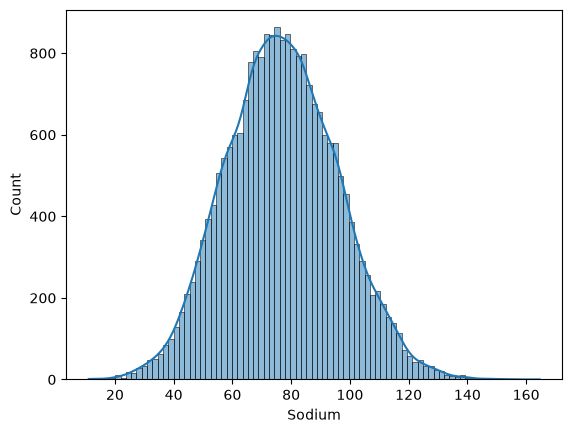

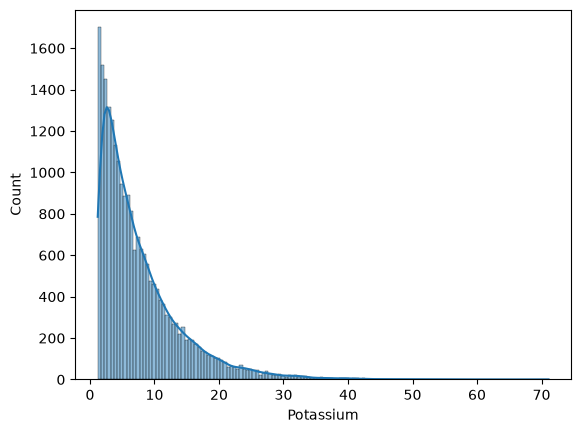

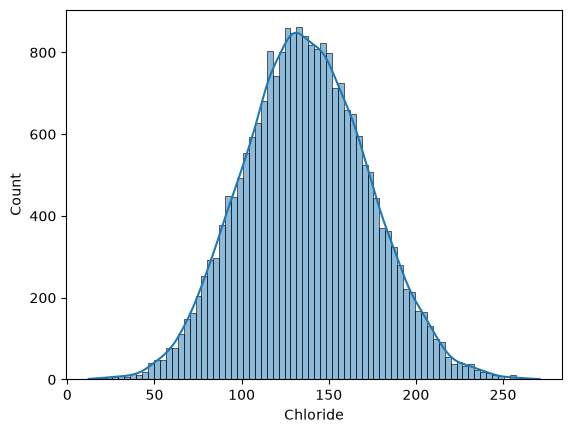

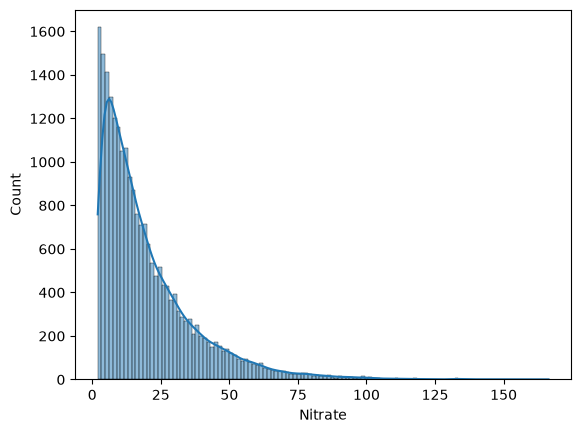

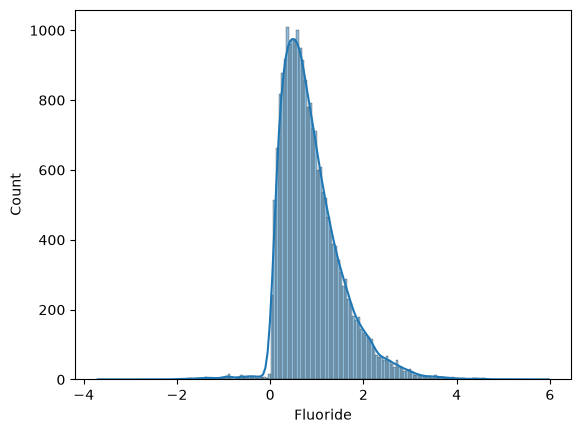

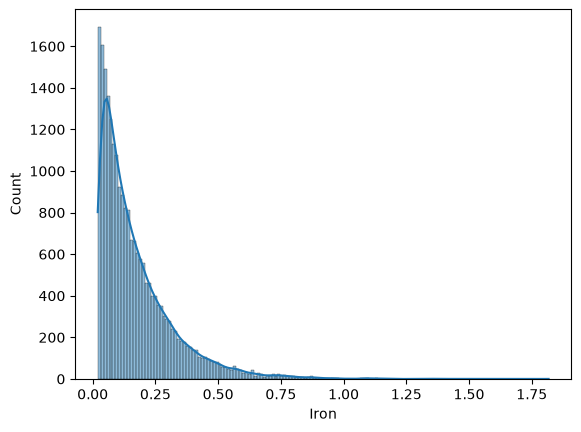

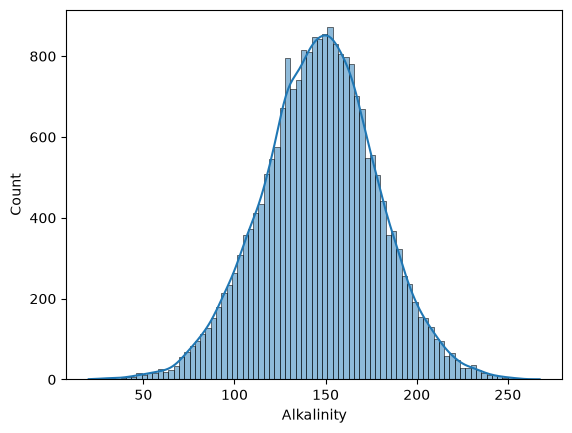

In [8]:
for col in df.columns[:-1]:
    sns.histplot(df[col], kde=True)
    plt.show()


In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
pH,22510.0,7.121158,1.114945,-1.500000,6.684351,7.100187,7.518510,2.200000e+01
Hardness,22610.0,192.266645,49.575249,-277.258229,175.461438,196.772879,216.005154,3.196982e+02
TDS,22513.0,24766.597888,37079.054981,0.000000,15667.156380,20963.886350,27318.944300,1.077300e+06
Chloramines,22610.0,7.113765,1.578813,1.329463,6.123458,7.111674,8.088267,1.321279e+01
Sulfate,22508.0,333.220041,41.250359,126.907723,307.355005,332.192512,359.161947,4.846980e+02
Conductivity,22610.0,427.435581,80.607891,198.168287,367.684729,423.379581,483.461394,7.591700e+02
Organic_carbon,22611.0,14.315506,3.322217,2.037624,12.089869,14.254216,16.657093,2.712349e+01
Trihalomethanes,22611.0,66.252444,16.109218,7.595681,55.800964,66.170779,77.150067,1.248759e+02
Turbidity,22510.0,4.432458,5.542792,0.000000,3.437564,3.967568,4.524813,1.096449e+02
Calcium,22610.0,74.374001,13.438043,15.114997,66.062591,74.591452,82.918914,1.268520e+02


## 2. Data quality and cleaning

First inspect missingness, duplicates, ranges, and distributions. Keep the original observations in `raw_df`. For each task, select rows based on that task's target and impute predictors inside its model pipeline; this avoids dropping a pH label because an unrelated classification field is missing.

In [10]:
df.duplicated().sum()


np.int64(3887)

In [11]:
df=df.drop_duplicates()

In [12]:
# Calculate the 99th percentile threshold
df = df.drop(df[(df["pH"] < 0) | (df["pH"] > 14)].index)


In [13]:
df[df['pH']>14].shape

(0, 19)

In [14]:
df = df.drop(df[df["Hardness"] < 0].index)

In [15]:
df= df[(df["TDS"] >= 50) & (df["TDS"] <= 50000)].reset_index(
    drop=True
)

In [16]:
df = df.drop(df[df["Fluoride"] < 0].index).reset_index(drop=True)

In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
pH,21850.0,7.081106,0.699994,0.200000,6.684351,7.097742,7.512030,9.639608
Hardness,21899.0,195.869165,32.807784,70.565172,176.487877,197.076649,216.227410,319.698249
TDS,21899.0,21815.451130,8476.138372,133.296798,15598.533585,20771.927310,27068.503185,49972.296600
Chloramines,21899.0,7.119853,1.577111,1.329463,6.129759,7.115563,8.092417,13.212788
Sulfate,21852.0,333.397757,40.821190,177.262347,307.555407,332.240844,359.122668,484.698035
Conductivity,21899.0,427.444384,80.584646,198.168287,367.629287,423.525698,483.398843,759.170020
Organic_carbon,21899.0,14.318789,3.325857,2.037624,12.091826,14.262869,16.658770,27.123489
Trihalomethanes,21899.0,66.222667,16.094085,7.595681,55.776961,66.158302,77.145482,124.875935
Turbidity,21852.0,3.956763,0.784128,0.000000,3.432791,3.957599,4.506909,6.553786
Calcium,21898.0,74.399651,13.439665,15.114997,66.091209,74.615723,82.921452,126.851968


In [18]:
df[df['Nitrate']>100].shape

(86, 19)

In [19]:
df = df.drop(df[df["Nitrate"] >100].index).reset_index(drop=True)

In [20]:
df[df['Potassium']>40].shape

(57, 19)

In [21]:
df = df.drop(df[df["Potassium"] >40].index).reset_index(drop=True)

In [22]:
df.shape

(21756, 19)

In [23]:
df.head()

,pH,Hardness,TDS,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Calcium,Magnesium,Sodium,Potassium,Chloride,Nitrate,Fluoride,Iron,Alkalinity,Potability
0,7.159102,150.155773,16052.651840,5.685047,374.464185,352.121528,11.587073,75.046610,4.966698,61.504002,21.006579,62.345970,2.192344,135.643193,5.561354,1.520887,0.169315,116.950616,0.0
1,6.990053,212.120116,15569.182870,6.872750,319.992702,443.547183,18.268341,123.893737,2.868158,85.238809,28.953441,79.458626,10.197039,168.585701,61.612777,0.786435,0.065204,152.949912,0.0
2,7.110356,204.571035,8183.078691,5.986018,416.595049,311.932109,12.701190,67.312776,4.264031,77.150948,30.591307,62.537654,10.996049,97.220908,9.129196,0.688611,0.124803,153.344413,1.0
3,5.500103,150.299555,25303.762810,7.147440,352.099179,526.743300,15.772748,51.344206,3.407067,58.647298,17.553237,110.628270,12.754797,196.460217,5.390290,1.300669,0.064911,106.874981,0.0
4,6.171355,210.286583,12656.723620,9.167730,349.388214,597.384394,10.761081,90.919973,4.769402,73.005793,30.096941,103.140817,12.468479,180.730654,51.619932,1.479490,0.126527,154.240181,0.0


In [24]:
df.isnull().sum()

pH                 49
Hardness            0
TDS                 0
Chloramines         0
Sulfate            47
Conductivity        0
Organic_carbon      0
Trihalomethanes     0
Turbidity          47
Calcium             1
Magnesium           1
Sodium              1
Potassium           1
Chloride            1
Nitrate            51
Fluoride            1
Iron                1
Alkalinity          1
Potability          1
dtype: int64

In [25]:
df.skew().sort_values()


pH                -2.246801
Calcium           -0.096251
Hardness          -0.096120
Trihalomethanes   -0.063947
Alkalinity        -0.060987
Magnesium         -0.047320
Turbidity         -0.025093
Organic_carbon    -0.014599
Sulfate            0.038669
Chloramines        0.040058
Chloride           0.087379
Sodium             0.122891
Conductivity       0.284691
Potability         0.446816
TDS                0.536467
Fluoride           1.456500
Nitrate            1.610478
Potassium          1.684226
Iron               2.056916
dtype: float64

In [26]:
df.isnull().sum()

pH                 49
Hardness            0
TDS                 0
Chloramines         0
Sulfate            47
Conductivity        0
Organic_carbon      0
Trihalomethanes     0
Turbidity          47
Calcium             1
Magnesium           1
Sodium              1
Potassium           1
Chloride            1
Nitrate            51
Fluoride            1
Iron                1
Alkalinity          1
Potability          1
dtype: int64

In [27]:
df.shape

(21756, 19)

In [28]:
df.skew().sort_values()

pH                -2.246801
Calcium           -0.096251
Hardness          -0.096120
Trihalomethanes   -0.063947
Alkalinity        -0.060987
Magnesium         -0.047320
Turbidity         -0.025093
Organic_carbon    -0.014599
Sulfate            0.038669
Chloramines        0.040058
Chloride           0.087379
Sodium             0.122891
Conductivity       0.284691
Potability         0.446816
TDS                0.536467
Fluoride           1.456500
Nitrate            1.610478
Potassium          1.684226
Iron               2.056916
dtype: float64

In [29]:
df['pH'] = df['pH'].fillna(df['pH'].median())

In [30]:
df.isnull().sum()

pH                  0
Hardness            0
TDS                 0
Chloramines         0
Sulfate            47
Conductivity        0
Organic_carbon      0
Trihalomethanes     0
Turbidity          47
Calcium             1
Magnesium           1
Sodium              1
Potassium           1
Chloride            1
Nitrate            51
Fluoride            1
Iron                1
Alkalinity          1
Potability          1
dtype: int64

In [31]:
df['Sulfate'] = df['Sulfate'].fillna(df['Sulfate'].mean())


In [32]:
df['Turbidity'] = df['Turbidity'].fillna(df['Turbidity'].mean())

In [33]:
df['Nitrate'] = df['Nitrate'].fillna(df['Nitrate'].median())

In [34]:
df.shape

(21756, 19)

<Axes: >

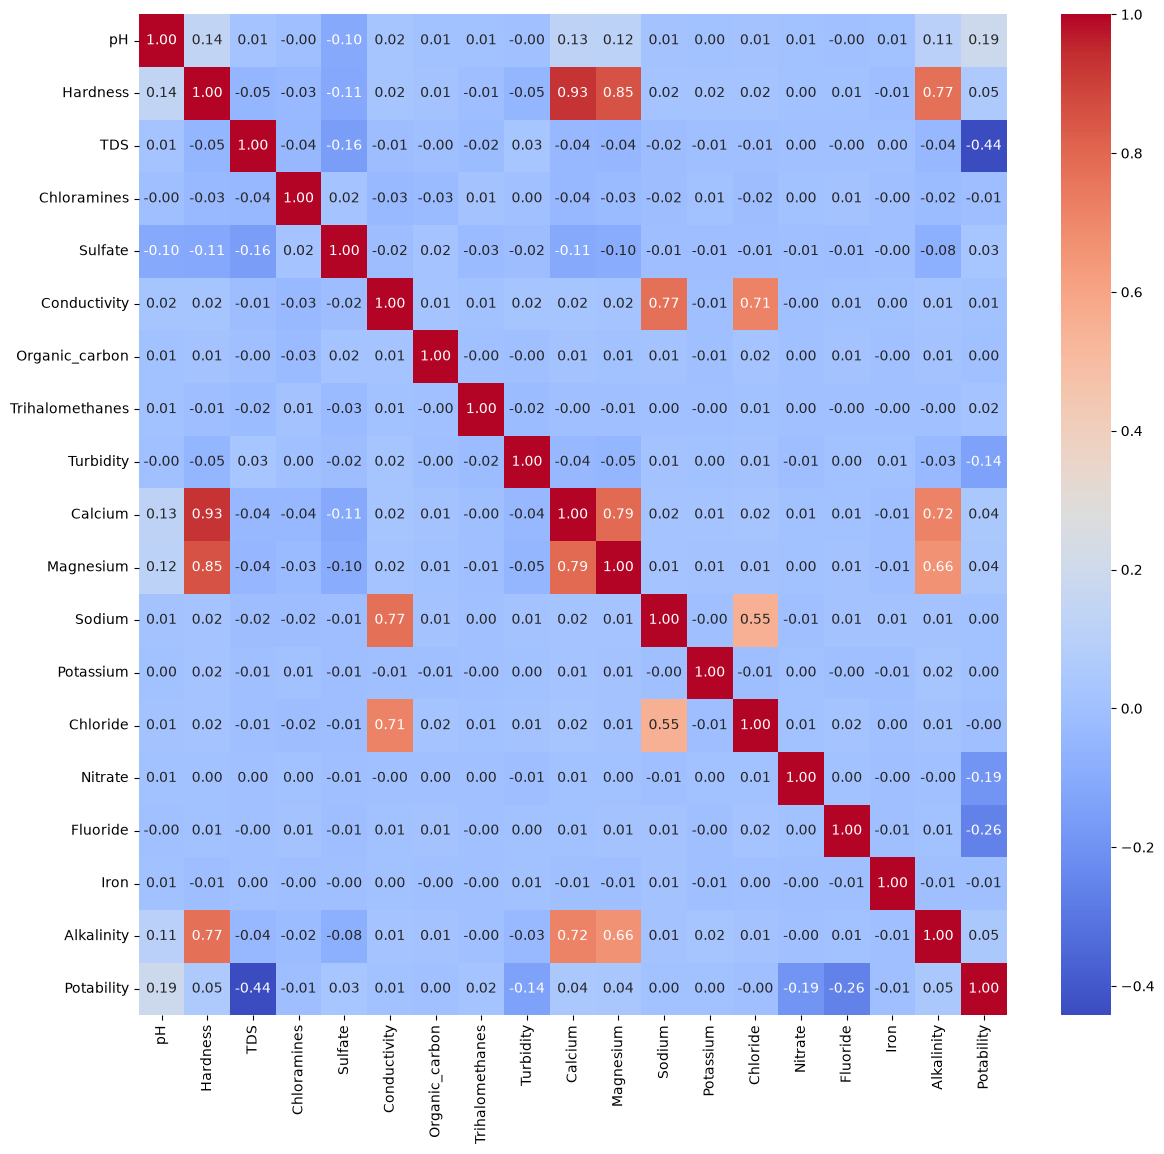

In [35]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(14,13))
sns.heatmap(corr,
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

In [36]:
df[(df['pH'] > 6.5) & (df['pH'] < 8.5)]['Potability'].value_counts()

Potability
0.0    9452
1.0    8493
Name: count, dtype: int64

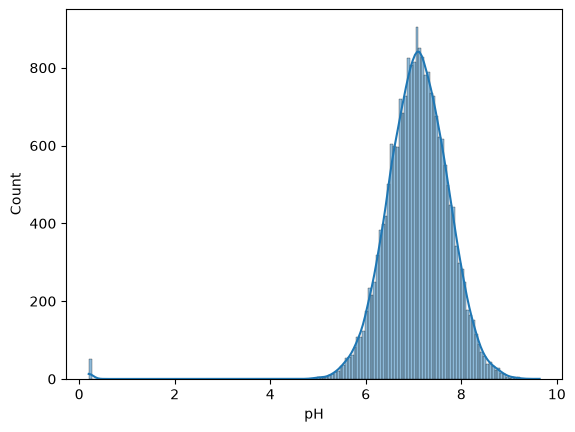

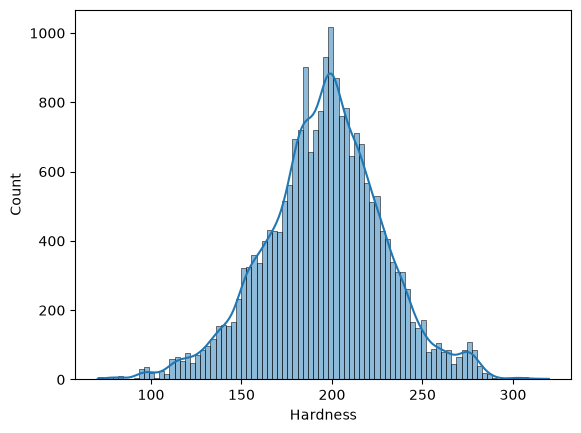

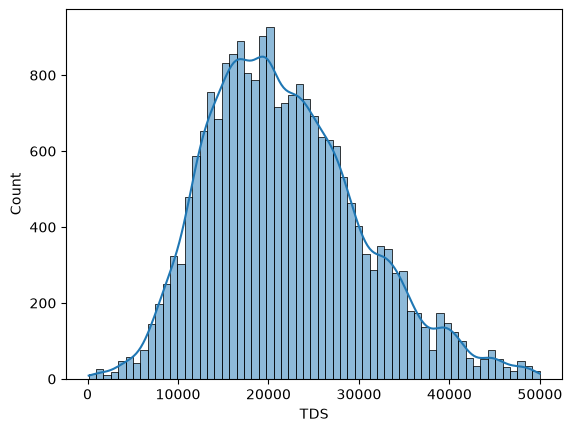

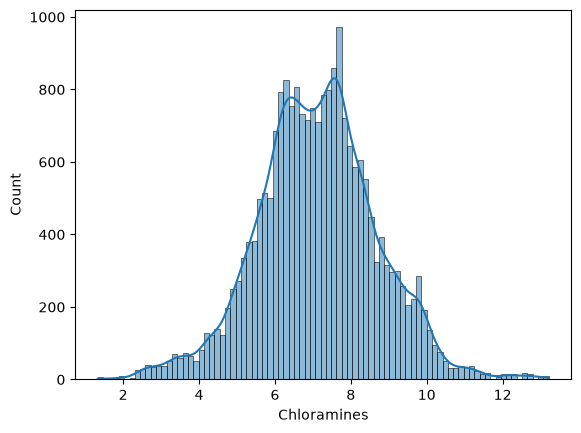

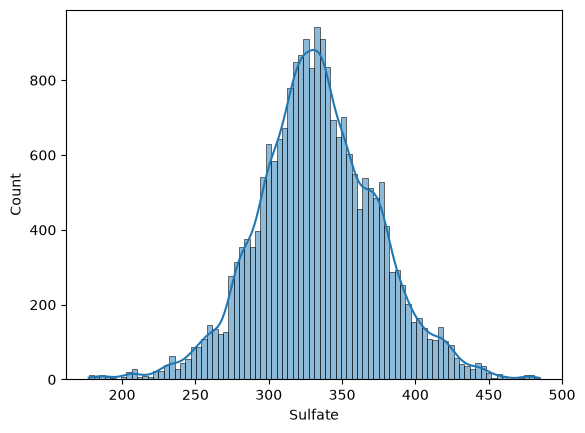

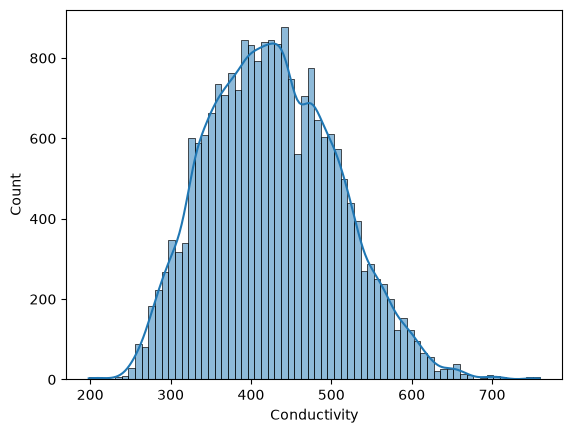

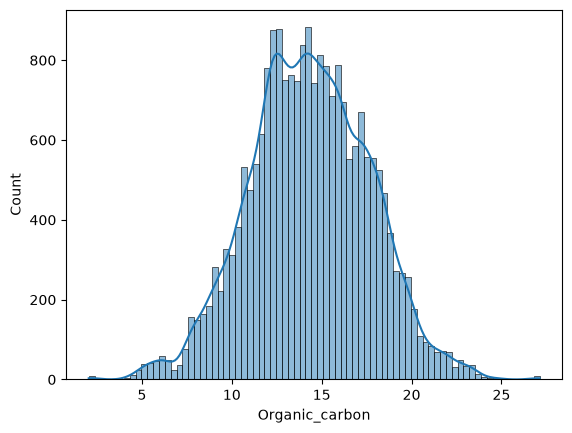

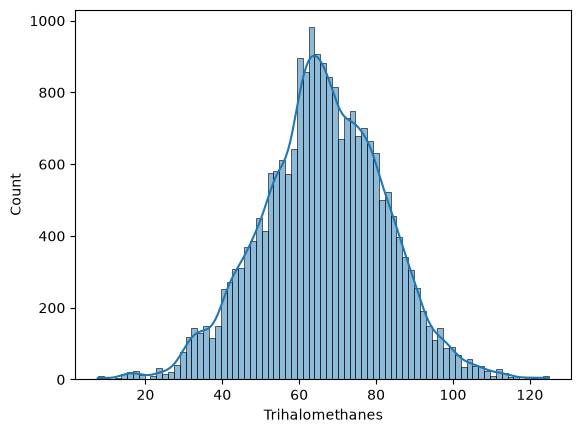

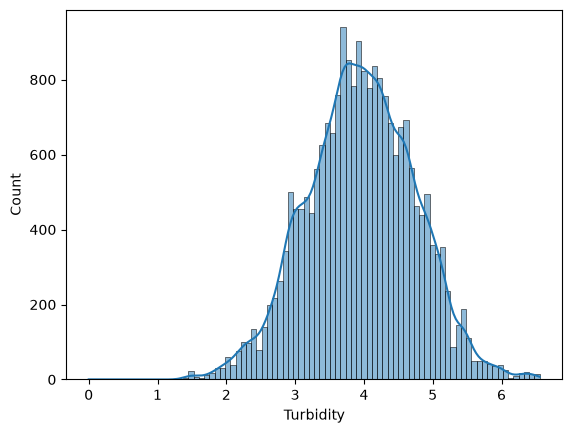

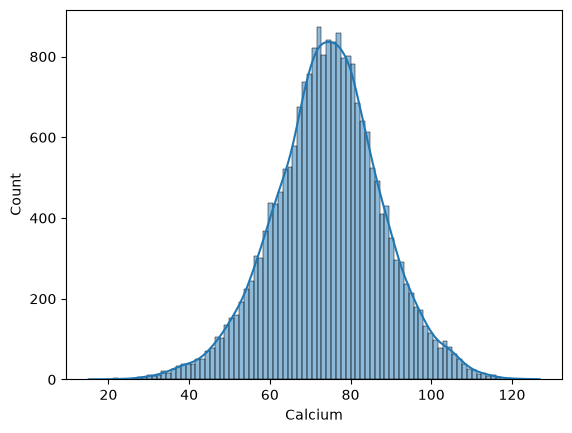

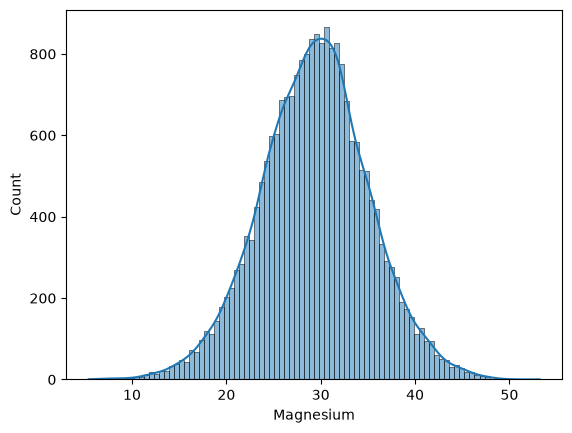

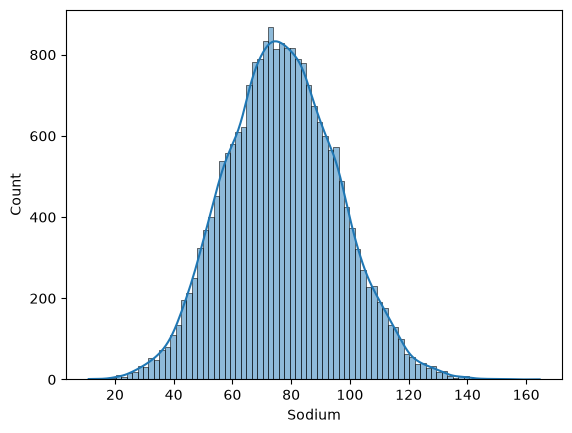

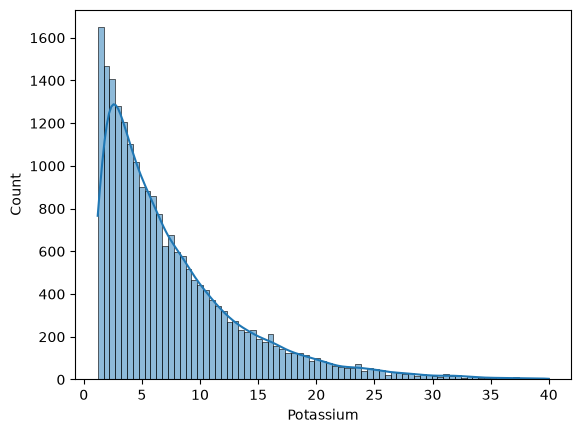

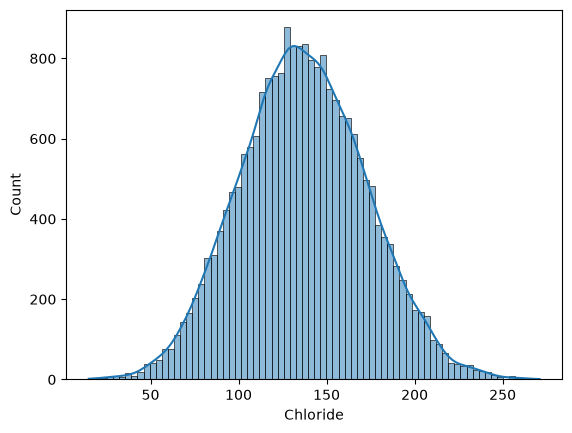

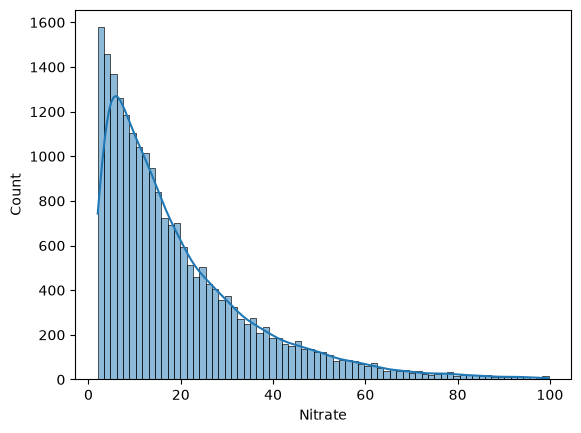

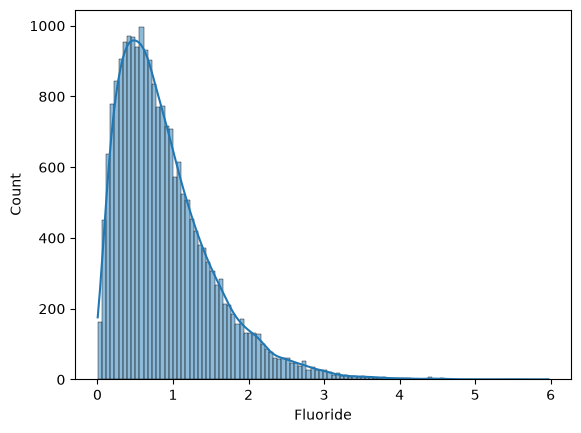

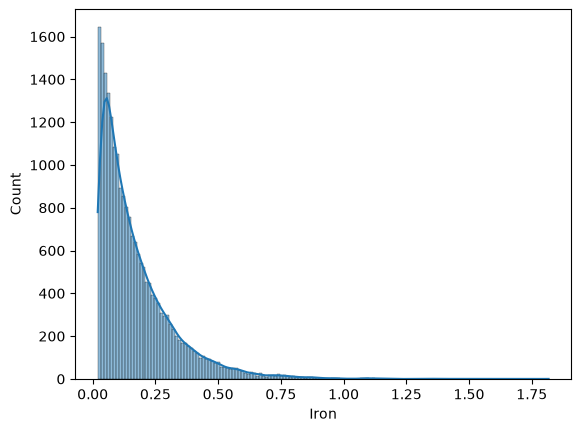

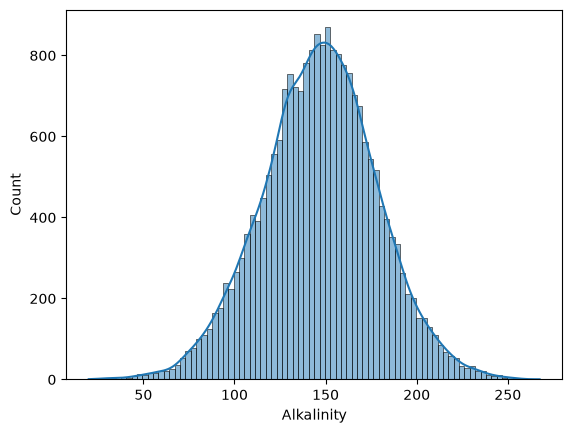

In [37]:
for col in df.columns[:-1]:
    sns.histplot(df[col], kde=True)
    plt.show()


In [38]:
df.isnull().sum()

pH                 0
Hardness           0
TDS                0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Calcium            1
Magnesium          1
Sodium             1
Potassium          1
Chloride           1
Nitrate            0
Fluoride           1
Iron               1
Alkalinity         1
Potability         1
dtype: int64

In [39]:
df=df.dropna()

In [40]:
x= df[['Turbidity', 'Hardness', 'TDS','Fluoride','Nitrate','Conductivity']]
y = df['Potability']

In [41]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.23,random_state=15)

In [43]:
from sklearn.ensemble import RandomForestClassifier,AdaBoostClassifier,GradientBoostingClassifier
import xgboost as xgb
import lightgbm as lgb

In [44]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report

In [45]:
def evulate_model(true,predicted):
    score = accuracy_score(true,predicted)
    matrix = confusion_matrix(true,predicted)
    report = classification_report(true,predicted)

    return score,matrix,report

In [46]:
models = {
    
    
    "Random Forest Classifier": RandomForestClassifier(),
    "AdaBoost Classifier": AdaBoostClassifier(),
    "Gradient Boost Classifier": GradientBoostingClassifier(),
    
    "XGBoost Classifier": xgb.XGBClassifier(),
    "LightGBM CLassifier": lgb.LGBMClassifier()
}

In [47]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=10,
    min_samples_leaf=5,
    max_features=None,
    random_state=42,
    n_jobs=-1
)

model.fit(x_train, y_train)

print("Training score:", model.score(x_train, y_train))
print("Test score:", model.score(x_test, y_test))

Training score: 0.9157065249835831
Test score: 0.9222621902478018


In [48]:
x_test.iloc[0]

Turbidity          5.536175
Hardness         254.711507
TDS             9284.805923
Fluoride           1.058422
Nitrate            6.854718
Conductivity     347.768049
Name: 20685, dtype: float64

In [49]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = model.predict(x_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[2625  388]
 [   1 1990]]
              precision    recall  f1-score   support

         0.0       1.00      0.87      0.93      3013
         1.0       0.84      1.00      0.91      1991

    accuracy                           0.92      5004
   macro avg       0.92      0.94      0.92      5004
weighted avg       0.93      0.92      0.92      5004



In [50]:
import xgboost as xgb
import lightgbm as lgb
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import classification_report, accuracy_score

# 1. Initialize the base models
# Note: XGBoost uses 'logloss' as the default evaluation metric for binary classification.
models = {
    "AdaBoost Classifier": AdaBoostClassifier(random_state=42),
    "Gradient Boost Classifier": GradientBoostingClassifier(random_state=42),
    "XGBoost Classifier": xgb.XGBClassifier(random_state=42, eval_metric='logloss'),
    "LightGBM Classifier": lgb.LGBMClassifier(random_state=42)
}

# 2. Define the hyperparameter search space for fine-tuning
param_grids = {
    "AdaBoost Classifier": {
        'n_estimators': [50, 100, 200],
        'learning_rate': [0.01, 0.1, 0.5, 1.0]
    },
    "Gradient Boost Classifier": {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7],
        'min_samples_split': [2, 5, 10]
    },
    "XGBoost Classifier": {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.1, 0.2],
        'max_depth': [3, 5, 7],
        'subsample': [0.8, 1.0],         # Randomly sample training instances to prevent overfitting
        'colsample_bytree': [0.8, 1.0]   # Randomly sample features per tree
    },
    "LightGBM Classifier": {
        'n_estimators': [100, 200, 300],
        'learning_rate': [0.01, 0.1, 0.2],
        'num_leaves': [31, 50, 70],      # Controls tree complexity; leaf-wise growth is used
        'max_depth': [3, 5, 7],
        'min_child_samples': [20, 30, 50] # Required samples per leaf to prevent over-fitting
    }
}

# 3. Execute tuning and evaluate models
# Assuming X_train, X_test, y_train, y_test are already defined in your environment
best_models = {}

for name, model in models.items():
    print(f"--- Fine-Tuning: {name} ---")
    
    # Using RandomizedSearchCV to find optimal parameters efficiently
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grids[name],
        n_iter=15,          # Tries 15 random parameter combinations from the grid
        cv=5,               # 5-fold cross-validation
        scoring='accuracy', # Optimizing for accuracy
        random_state=42,
        n_jobs=-1           # Utilize all CPU cores
    )
    
    # Fit the model on training data
    search.fit(x_train, y_train)
    
    # Extract the tuned model
    best_model = search.best_estimator_
    best_models[name] = best_model
    
    # Generate predictions on unseen test data
    y_pred = best_model.predict(x_test)
    
    # Output performance metrics
    print(f"Best Parameters Found: {search.best_params_}")
    print(f"Test Accuracy: {accuracy_score(y_test, y_pred):.4f}")
    print("Classification Report:")
    print(classification_report(y_test, y_pred))
    print("-" * 40 + "\n")

--- Fine-Tuning: AdaBoost Classifier ---
Best Parameters Found: {'n_estimators': 50, 'learning_rate': 0.5}
Test Accuracy: 0.9207
Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      0.87      0.93      3013
         1.0       0.83      1.00      0.91      1991

    accuracy                           0.92      5004
   macro avg       0.92      0.93      0.92      5004
weighted avg       0.93      0.92      0.92      5004

----------------------------------------

--- Fine-Tuning: Gradient Boost Classifier ---
Best Parameters Found: {'n_estimators': 100, 'min_samples_split': 10, 'max_depth': 3, 'learning_rate': 0.1}
Test Accuracy: 0.9215
Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      0.87      0.93      3013
         1.0       0.84      1.00      0.91      1991

    accuracy                           0.92      5004
   macro avg       0.92      0.93      0.92      5004
weighte

In [51]:
df.tail()

,pH,Hardness,TDS,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Calcium,Magnesium,Sodium,Potassium,Chloride,Nitrate,Fluoride,Iron,Alkalinity,Potability
21751,6.658465,162.275071,29888.332960,8.491284,334.073743,494.504791,16.892654,69.668918,5.209649,62.549395,32.659630,82.564049,3.583788,166.063205,6.061749,1.934385,0.266025,148.223504,0.0
21752,6.517474,167.861577,25263.713550,8.026397,333.659523,405.125364,18.239856,70.150454,2.845312,62.413879,26.137384,87.268487,11.526699,174.610124,35.905101,1.411149,0.088565,131.149262,0.0
21753,7.370451,194.602620,27809.243930,6.884763,330.392370,556.200527,22.630335,82.048327,4.969195,71.532261,31.449473,94.066448,2.925427,210.300067,58.024052,1.501053,0.279564,127.979185,0.0
21754,7.278545,171.006346,8661.545542,9.572903,436.673898,306.144704,10.933359,91.733094,3.895950,63.566964,31.428899,62.601301,5.614161,110.096862,2.381872,0.851455,0.096129,105.963438,1.0
21755,6.936748,217.730121,22590.651980,7.368259,305.053727,380.004239,18.683455,53.917263,3.620675,86.414580,30.272728,58.364887,1.644220,135.162962,3.137769,0.086197,0.407592,203.874842,1.0


MODEL B REGRESSION TO FIND PH


## 5. pH regression: target-focused analysis

For pH prediction, use pH as the target and exclude it from predictors. Potability is also excluded because it is a separate label and would not normally be available as a chemistry measurement at prediction time. Missing pH targets are omitted; missing predictor values are imputed inside each pipeline. The held-out test set is reserved for final comparison.

<Axes: >

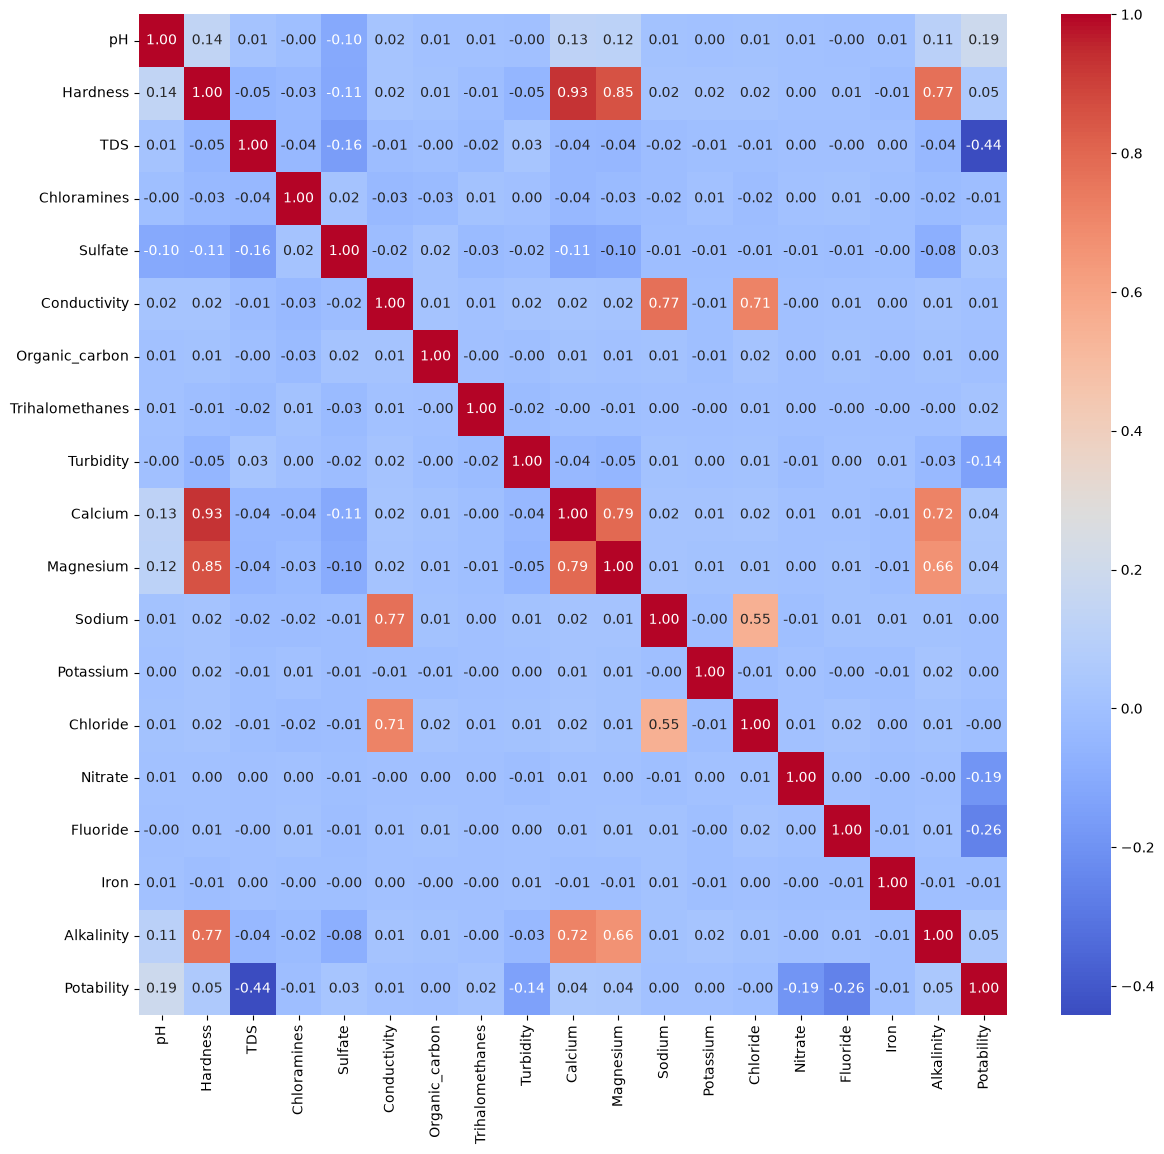

In [53]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(14,13))
sns.heatmap(corr,
            annot=True,
            cmap="coolwarm",
            fmt=".2f")

In [54]:
# The source files use different names for dissolved solids; preserve the source column.
ph_feature_candidates = ['Hardness','Alkalinity','Potability']
ph_data = df.dropna(subset=['pH']).copy()
X_ph = ph_data[ph_feature_candidates]
y_ph = ph_data['pH'].astype(float)
X_ph_train, X_ph_test, y_ph_train, y_ph_test = train_test_split(
    X_ph, y_ph, test_size=0.20, random_state=45
)
print(f'pH labeled rows: {len(ph_data):,}; predictors: {len(ph_feature_candidates)}')
print('Predictors:', ph_feature_candidates)
print(f'Train rows: {len(X_ph_train):,}; test rows: {len(X_ph_test):,}')

pH labeled rows: 21,755; predictors: 3
Predictors: ['Hardness', 'Alkalinity', 'Potability']
Train rows: 17,404; test rows: 4,351


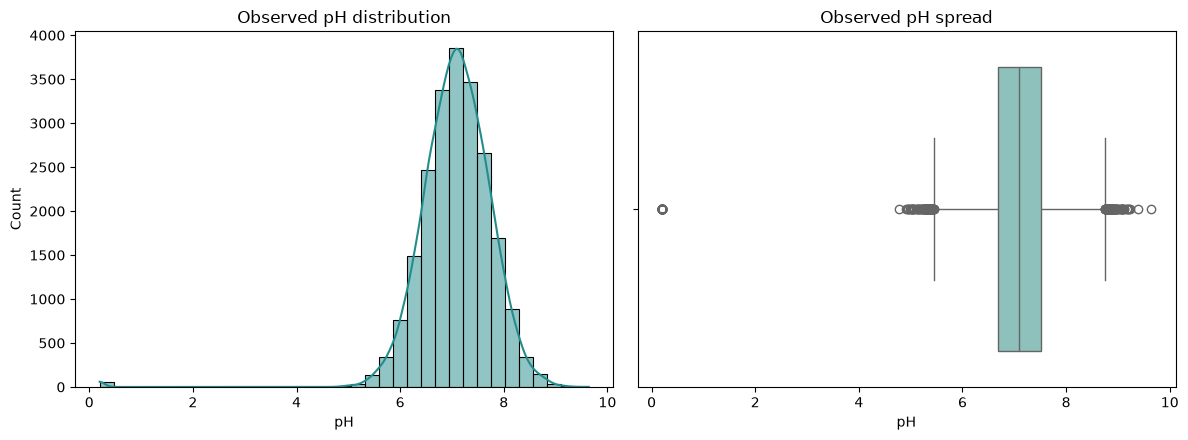

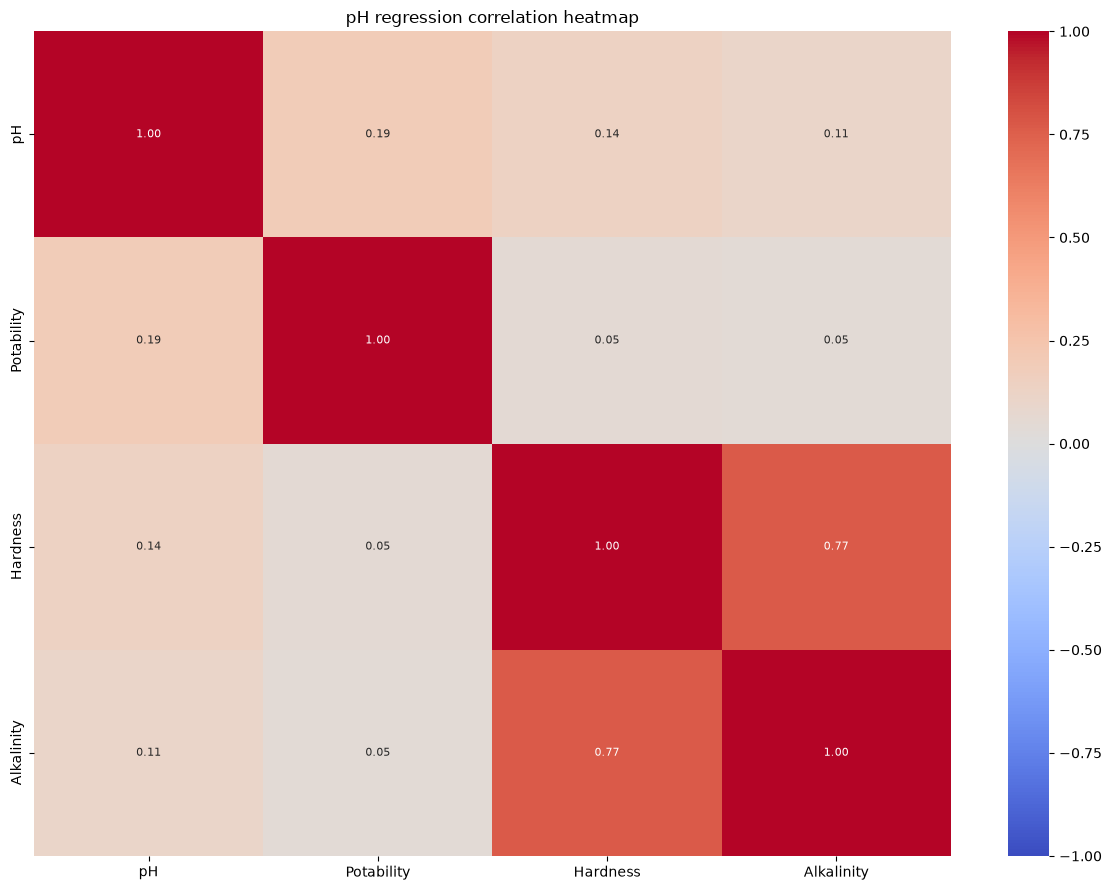

,correlation with pH
Potability,0.189451
Hardness,0.138745
Alkalinity,0.106338


In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12,4.5))
sns.histplot(y_ph, kde=True, bins=35, color='#258c8c', ax=axes[0])
axes[0].set(title='Observed pH distribution', xlabel='pH')
sns.boxplot(x=y_ph, ax=axes[1], color='#87c9c2')
axes[1].set(title='Observed pH spread', xlabel='pH')
plt.tight_layout(); plt.show()

# pH-only correlation heatmap, ordered by correlation with target.
ph_corr = ph_data[ph_feature_candidates + ['pH']].corr(numeric_only=True)
order = ph_corr['pH'].abs().sort_values(ascending=False).index
plt.figure(figsize=(12,9))
sns.heatmap(ph_corr.loc[order, order], cmap='coolwarm', center=0, vmin=-1, vmax=1,
            annot=True, fmt='.2f', annot_kws={'size':8})
plt.title('pH regression correlation heatmap')
plt.tight_layout(); plt.show()
display(ph_corr['pH'].drop('pH').sort_values(key=lambda s:s.abs(), ascending=False).rename('correlation with pH').to_frame())

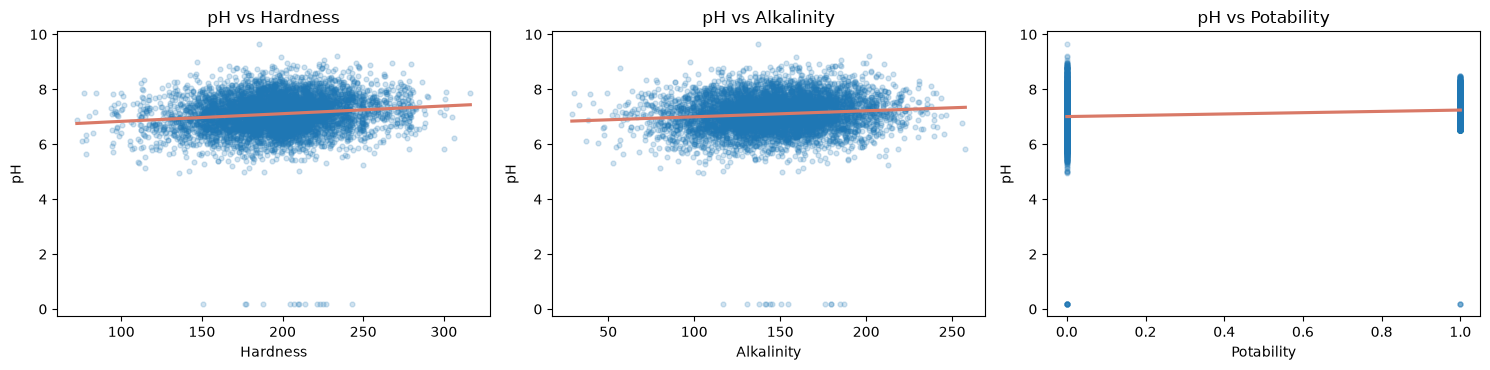

In [58]:
# Scatterplots for each chemistry feature against pH (sampled only for readable plotting).
plot_df = ph_data[ph_feature_candidates + ['pH']].dropna(subset=['pH'])
if len(plot_df) > 6000:
    plot_df = plot_df.sample(6000, random_state=45)
ncols=3; nrows=int(np.ceil(len(ph_feature_candidates)/ncols))
fig, axes=plt.subplots(nrows,ncols,figsize=(15,3.8*nrows)); axes=np.array(axes).reshape(-1)
for ax,col in zip(axes,ph_feature_candidates):
    sns.regplot(data=plot_df,x=col,y='pH',scatter_kws={'alpha':.2,'s':12},
                line_kws={'color':'#d97967'},ci=None,ax=ax)
    ax.set_title(f'pH vs {col}')
for ax in axes[len(ph_feature_candidates):]: ax.remove()
plt.tight_layout(); plt.show()

In [59]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

cv = KFold(n_splits=5, shuffle=True, random_state=45)
models_ph = {
    'Random Forest': Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),
                               ('model',RandomForestRegressor(n_estimators=350,min_samples_leaf=2,
                                                              max_features=1.0,random_state=45,n_jobs=-1))]),
    'Extra Trees': Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),
                             ('model',ExtraTreesRegressor(n_estimators=350,min_samples_leaf=2,
                                                          max_features=.9,random_state=45,n_jobs=-1))]),
    'Gradient Boosting': Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),
                                   ('model',GradientBoostingRegressor(n_estimators=250,learning_rate=.04,
                                                                      max_depth=2,loss='huber',random_state=45))]),
    'Histogram Gradient Boosting': Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),
                                             ('model',HistGradientBoostingRegressor(max_iter=250,learning_rate=.06,
                                                                                    l2_regularization=1,random_state=45))]),
    'Ridge': Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),
                       ('scale',StandardScaler()),('model',Ridge(alpha=10.0))]),
    'Polynomial Ridge': Pipeline([('imputer',SimpleImputer(strategy='median',add_indicator=True)),
                                  ('scale',StandardScaler()),
                                  ('poly',PolynomialFeatures(degree=2,include_bias=False)),
                                  ('model',Ridge(alpha=100.0))]),
    'PCA + Ridge': Pipeline([('imputer',SimpleImputer(strategy='median')),
                             ('scale',StandardScaler()),('pca',PCA(n_components=.95)),
                             ('model',Ridge(alpha=10.0))]),
}
results=[]
for name, estimator in models_ph.items():
    scores = cross_val_score(estimator, X_ph_train, y_ph_train, cv=cv,
                             scoring='neg_mean_absolute_error', n_jobs=-1)
    results.append({'Model':name,'CV MAE mean':-scores.mean(),'CV MAE std':scores.std()})
regression_results = pd.DataFrame(results).sort_values('CV MAE mean').reset_index(drop=True)
display(regression_results)
best_ph_name = regression_results.loc[0,'Model']
best_ph_model = models_ph[best_ph_name]
print('Selected by training CV MAE:', best_ph_name)

,Model,CV MAE mean,CV MAE std
0,Polynomial Ridge,0.489555,0.004916
1,Ridge,0.489659,0.005177
2,PCA + Ridge,0.489659,0.005177
3,Gradient Boosting,0.489775,0.005048
4,Histogram Gradient Boosting,0.491809,0.004675
5,Extra Trees,0.499818,0.004874
6,Random Forest,0.522314,0.005251


Selected by training CV MAE: Polynomial Ridge


Test MAE:  0.4927 pH units
Test RMSE: 0.6947 pH units
Test R?:   0.0336


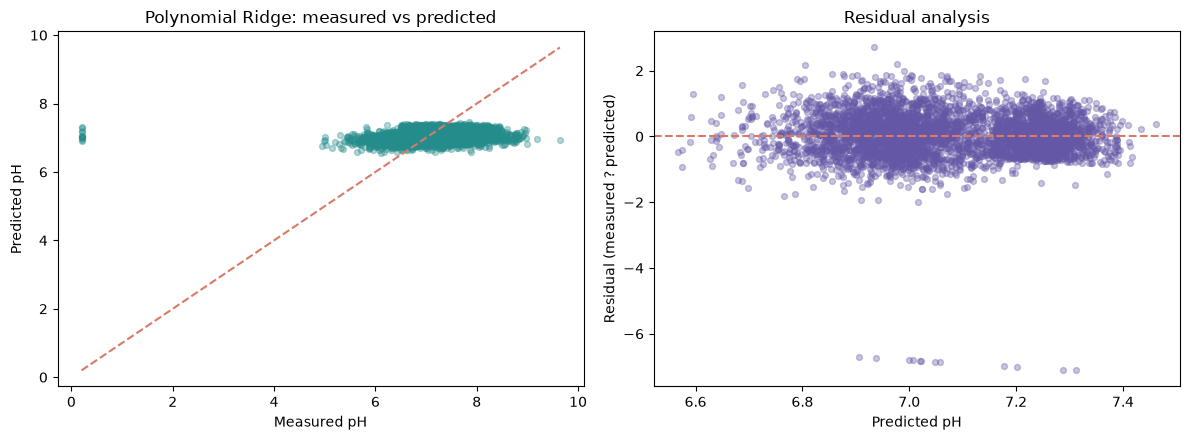

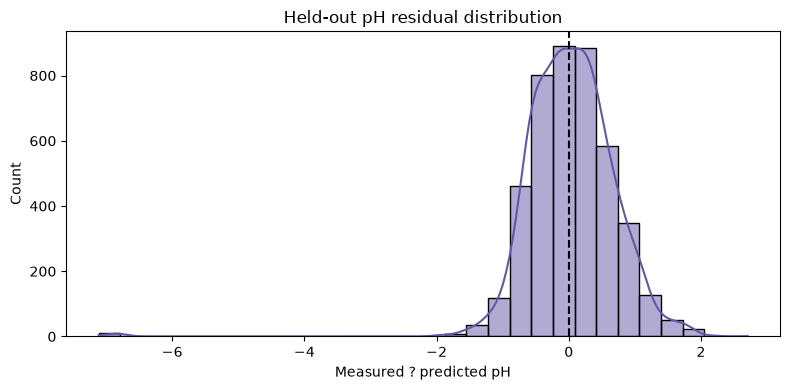

In [60]:
best_ph_model.fit(X_ph_train,y_ph_train)
y_ph_pred = best_ph_model.predict(X_ph_test)
ph_test_mae = mean_absolute_error(y_ph_test,y_ph_pred)
ph_test_rmse = mean_squared_error(y_ph_test,y_ph_pred)**0.5
ph_test_r2 = r2_score(y_ph_test,y_ph_pred)
print(f'Test MAE:  {ph_test_mae:.4f} pH units')
print(f'Test RMSE: {ph_test_rmse:.4f} pH units')
print(f'Test R?:   {ph_test_r2:.4f}')

fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].scatter(y_ph_test,y_ph_pred,s=18,alpha=.35,color='#258c8c')
lo=min(y_ph_test.min(),y_ph_pred.min()); hi=max(y_ph_test.max(),y_ph_pred.max())
axes[0].plot([lo,hi],[lo,hi],'--',color='#d97967')
axes[0].set(xlabel='Measured pH',ylabel='Predicted pH',title=f'{best_ph_name}: measured vs predicted')
residuals=y_ph_test-y_ph_pred
axes[1].scatter(y_ph_pred,residuals,s=18,alpha=.35,color='#6457a6')
axes[1].axhline(0,ls='--',color='#d97967')
axes[1].set(xlabel='Predicted pH',ylabel='Residual (measured ? predicted)',title='Residual analysis')
plt.tight_layout(); plt.show()

fig,ax=plt.subplots(figsize=(8,4))
sns.histplot(residuals,kde=True,bins=30,ax=ax,color='#6457a6')
ax.axvline(0,ls='--',color='black'); ax.set(title='Held-out pH residual distribution',xlabel='Measured ? predicted pH')
plt.tight_layout(); plt.show()

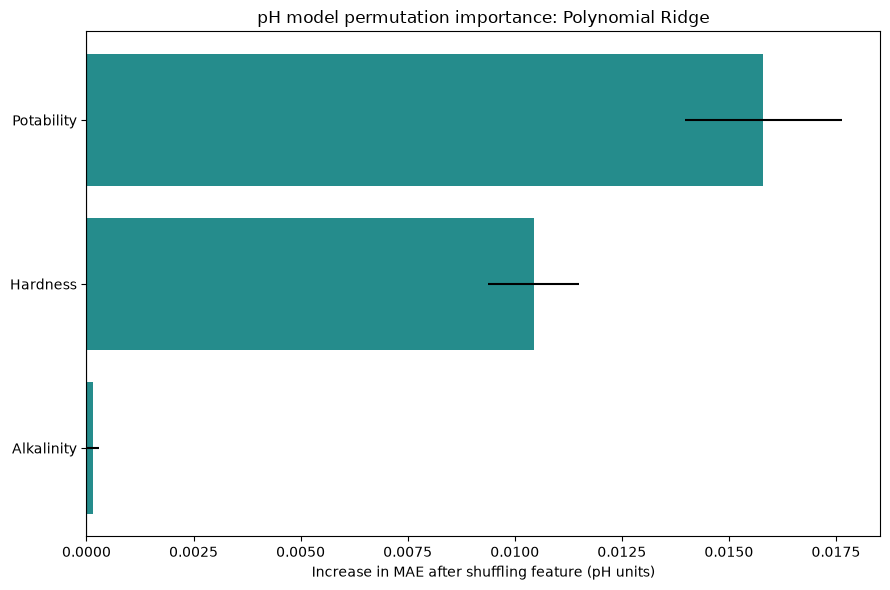

,feature,importance_mean,importance_std
2,Potability,0.015806,0.001840
0,Hardness,0.010440,0.001058
1,Alkalinity,0.000160,0.000140


In [62]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(best_ph_model,X_ph_test,y_ph_test,n_repeats=10,
                             random_state=45,n_jobs=-1,scoring='neg_mean_absolute_error')
importance = pd.DataFrame({'feature':X_ph_test.columns,'importance_mean':pi.importances_mean,
                           'importance_std':pi.importances_std}).sort_values('importance_mean')
plt.figure(figsize=(9,6))
plt.barh(importance.feature,importance.importance_mean,xerr=importance.importance_std,color='#258c8c')
plt.axvline(0,color='black',lw=.8)
plt.xlabel('Increase in MAE after shuffling feature (pH units)')
plt.title(f'pH model permutation importance: {best_ph_name}')
plt.tight_layout(); plt.show()
display(importance.sort_values('importance_mean',ascending=False))

Record the selected model, cross-validated MAE, held-out test MAE/RMSE/R?, and the important limitations. Compare PCA and feature-engineered models by the reported validation and test results rather than assuming extra transformations improve accuracy. Performance can change on samples from another location, season, or laboratory; validate externally before operational use.
